In [1]:
#| include: false
import math

import graphviz
import matplotlib.pyplot as plt
import numpy as np

from lab import setup

setup()

This notebook only exists to check the formatting. It has **bold**, *italics*, `inline code` and [a link to the micrograd repository](https://github.com/karpathy/micrograd).

## Text

A short list:

- The derivative tells you how fast a function changes.
- The chain rule lets you combine derivatives.
- Backpropagation applies the chain rule from the output back to the inputs.

A numbered list:

1. Run the forward pass.
2. Set the output gradient to 1.
3. Walk the graph backwards.

> A quote block, for a note that should stand apart from the text.

| Operation | Local derivative |
|---|---|
| $a + b$ | $1$ for both inputs |
| $a \cdot b$ | $b$ for $a$, $a$ for $b$ |
| $\tanh(x)$ | $1 - \tanh^2(x)$ |

## Math

Inline math sits in the sentence, like $f(x) = x^2$ and its derivative $f'(x) = 2x$. A dollar amount such as $5 stays plain text.

The derivative as a limit, on its own line:

$$f'(x) = \lim_{h \to 0} \frac{f(x + h) - f(x)}{h}$$

The chain rule:

$$\frac{\partial L}{\partial a} = \frac{\partial L}{\partial c} \cdot \frac{\partial c}{\partial a}$$

Several aligned lines, for a worked step by step:

$$\begin{aligned}
c &= a \cdot b \\
\frac{\partial c}{\partial a} &= b \\
\frac{\partial c}{\partial b} &= a
\end{aligned}$$

## Code

A cell with code and no output:

In [2]:
def f(x):
    return x**2


def slope(f, x, h=1e-6):
    return (f(x + h) - f(x)) / h

A cell that prints:

In [3]:
for h in [0.1, 0.01, 0.001, 0.0001]:
    print(f"h = {h:<7} slope = {slope(f, 1.5, h):.6f}")

h = 0.1     slope = 3.100000
h = 0.01    slope = 3.010000
h = 0.001   slope = 3.001000
h = 0.0001  slope = 3.000100


A cell whose last line is a value:

In [4]:
slope(f, 1.5), 2 * 1.5

(3.000000999620056, 3.0)

## Figures

A plot with its code and a caption:

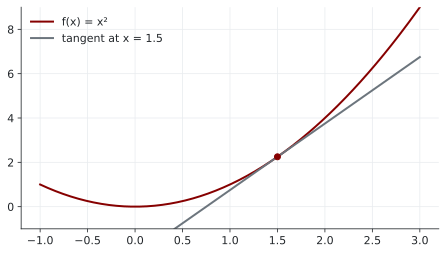

In [5]:
#| name: square-and-tangent
#| alt: The curve y equals x squared, with a straight tangent line touching it at x equals 1.5.
#| caption: The tangent at x = 1.5 has slope 3.
x = np.linspace(-1, 3, 200)
plt.plot(x, f(x), label="f(x) = x²")
plt.plot(x, f(1.5) + 3 * (x - 1.5), label="tangent at x = 1.5")
plt.scatter([1.5], [f(1.5)], zorder=3)
plt.ylim(-1, 9)
plt.legend()
plt.show()

A plot with the code hidden:

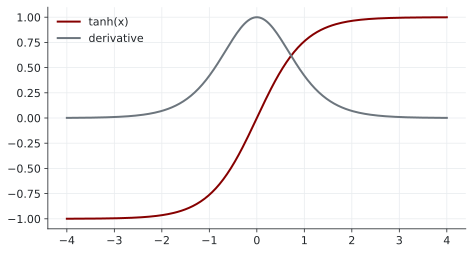

In [6]:
#| echo: false
#| name: tanh-and-derivative
#| alt: The tanh curve rising from minus one to one, and its derivative, a bump that peaks at one when x is zero.
x = np.linspace(-4, 4, 200)
plt.plot(x, np.tanh(x), label="tanh(x)")
plt.plot(x, 1 - np.tanh(x) ** 2, label="derivative")
plt.legend()
plt.show()

A small computation graph, drawn with Graphviz:

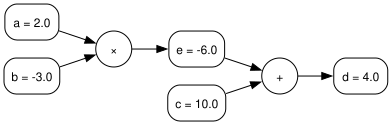

In [7]:
#| name: graph
#| alt: A graph where a and b feed a multiply node, whose result and c feed an add node that outputs d.
graph = graphviz.Digraph(
    graph_attr={"rankdir": "LR"},
    node_attr={"fontname": "Helvetica", "fontsize": "12", "shape": "box", "style": "rounded"},
)
graph.node("a", "a = 2.0")
graph.node("b", "b = -3.0")
graph.node("c", "c = 10.0")
graph.node("mul", "×", shape="circle")
graph.node("e", "e = -6.0")
graph.node("add", "+", shape="circle")
graph.node("d", "d = 4.0")
graph.edges([
    ("a", "mul"), ("b", "mul"), ("mul", "e"),
    ("e", "add"), ("c", "add"), ("add", "d"),
])
graph

That is everything a page can show. The real experiments start from here.